# NEURAL NETWORKS AND DEEP LEARNING

---

## Project by Alberto Granati - A Comparative Study of Periodicity and Padding in TimesNet for Multivariate Time-Series Anomaly Detection

This notebook applies **TimesNet** to multivariate anomaly detection on the **SMD dataset**.

The project compares:

1. **1D convolution without periodicity (`dim = 0`)**: direct 1D temporal convolutions, without FFT and without the 2D transformation.
2. **1D convolution with periodicity (`dim = 1`)**: 1D temporal convolutions, with FFT and without the 2D transformation.
3. **Periodic TimesNet (`dim = 2`)**: FFT, dominant periods, 2D temporal representation and 2D convolutions.
4. **Periodic Fractional TimesNet (`dim = 3`)**: Padding is done not at the end of the timeseries, but at each period repeating the last value

The four variants use the same dataset, embedding, number of layers, training procedure, reconstruction loss and anomaly threshold, starting from the values assigned in the paper of "TimesNet: temporal 2D-variation modelink for general time series analysis". 

### Learning goals

By the end of this notebook, we should be able to see which are the charateristics of TimesNet that makes it very powerful to detect anomalies in time series.
Moreover we will test also the modification suggested in "Improvement of Anomaly Detection Through Enhanced Feature Extraction in TimesNet" on the SMD dataset and see if the performance are improving or not.


# Setup

The notebook is self-contained and uses only the files stored in:

```text
dataset/SMD/
```

`project.ipynb` and the `dataset` folder have the same parent directory

In [1]:
import time
import random
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import math

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.preprocessing import StandardScaler

The parameters are fix to the values find when possible in the paper in which TimesNet is introduced, while the remaining ones are the default values that can be found in the github directory of TimesNet source code. In this way, we can work with a standard pipeline for all the architectures.

In [2]:
# Main experiment parameters
DATA_DIR = Path("./dataset/SMD")

# as timesNet paper says
seq_len = 100
step = 100

batch_size = 128
num_workers = 0

d_model = 64
d_ff = 64
e_layers = 3
top_k = 3
num_kernels = 6
dropout = 0.1

learning_rate = 1e-4
train_epochs = 10
patience = 3
anomaly_ratio = 0.5

seed = 2022
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Current folder:", Path.cwd())
print("Selected device:", device)

Current folder: c:\Users\albig\Documents\uni\magistrale\deepLearning\progetto\consegna
Selected device: cuda


# Dataset

SMD contains:

- a normal training sequence;
- a test sequence containing both normal and anomalous points;
- one binary test label for each temporal point.

The scaler is fitted only on the training data and is then applied to the validation and test data.

In [3]:
# Load the local SMD files
train_raw = np.load(DATA_DIR / "SMD_train.npy").astype(np.float32)
test_raw = np.load(DATA_DIR / "SMD_test.npy").astype(np.float32)
test_labels = np.load(DATA_DIR / "SMD_test_label.npy").reshape(-1).astype(np.int64)

print("Train shape:", train_raw.shape)
print("Test shape:", test_raw.shape)
print("Test labels shape:", test_labels.shape)

# check that the data are obtained
assert train_raw.ndim == 2
assert test_raw.ndim == 2
assert train_raw.shape[1] == test_raw.shape[1]
assert len(test_raw) == len(test_labels)

Train shape: (708405, 38)
Test shape: (708420, 38)
Test labels shape: (708420,)


In [4]:
# Temporal train-validation split
# The first 80% is used for training, the last 20% for validation.
split_index = int(len(train_raw) * 0.8)

train_raw_split = train_raw[:split_index]
val_raw = train_raw[split_index:]

# Standardization
# The scaler is fitted only on the training split to avoid data leakage.
scaler = StandardScaler()

train_data = scaler.fit_transform(train_raw_split).astype(np.float32)
val_data = scaler.transform(val_raw).astype(np.float32)
test_data = scaler.transform(test_raw).astype(np.float32)

n_features_train = train_data.shape[1]
n_features_val = val_data.shape[1]
n_features_test = test_data.shape[1]

dataset_summary = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "time points": [
        len(train_data),
        len(val_data),
        len(test_data)
    ],
    "features": [
        n_features_train,
        n_features_val,
        n_features_test
    ],
    "anomalous points": [ # TODO: check
        0,
        0,
        int(test_labels.sum())
    ]
})

display(dataset_summary)

,split,time points,features,anomalous points
0,train,566724,38,0
1,validation,141681,38,0
2,test,708420,38,29444


Let's visualized two differents features with their values and the corrisponding ground truth

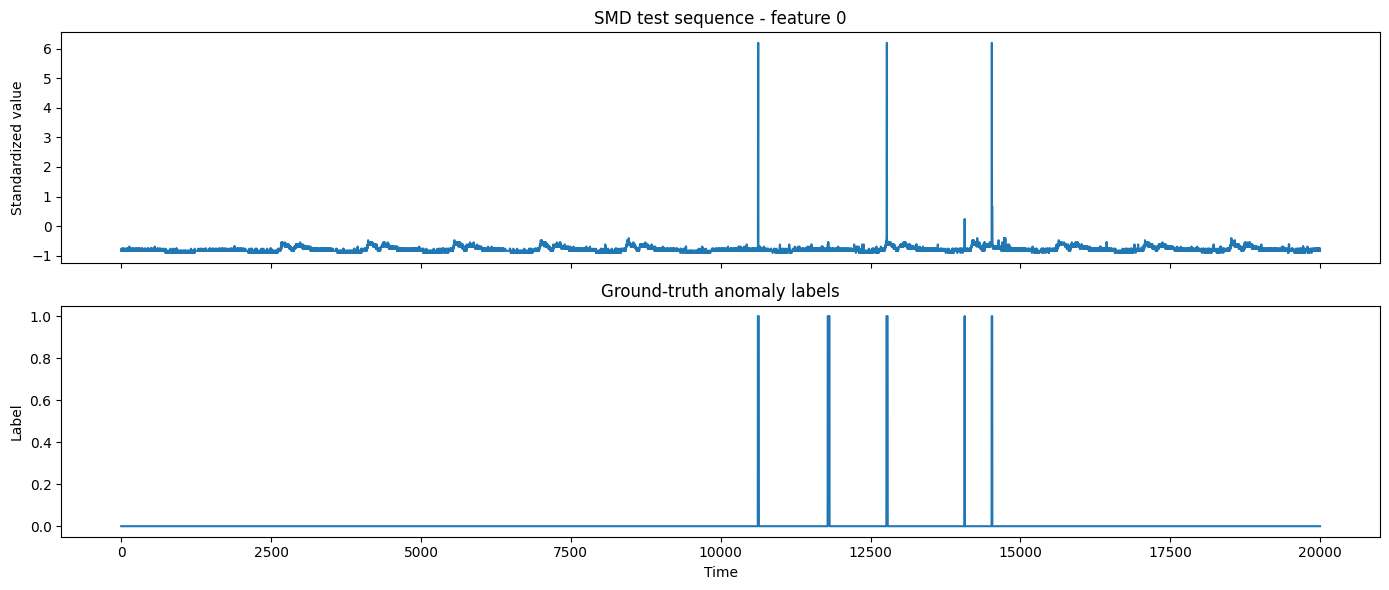

In [5]:
# Visualize one feature and the corresponding test labels
feature = 0
start = 0
end = 20000

fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

ax[0].plot(test_data[start:end, feature])
ax[0].set_title(f"SMD test sequence - feature {feature}")
ax[0].set_ylabel("Standardized value")

ax[1].plot(test_labels[start:end])
ax[1].set_title("Ground-truth anomaly labels")
ax[1].set_xlabel("Time")
ax[1].set_ylabel("Label")

plt.tight_layout()
plt.show()

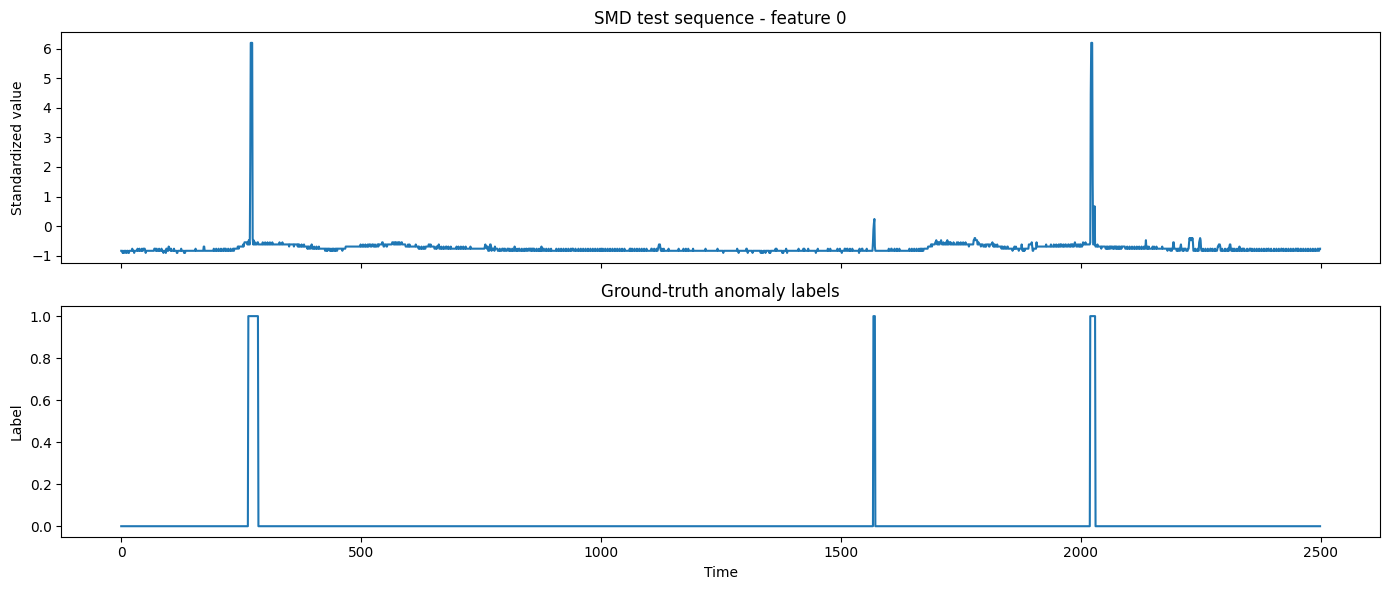

In [6]:
# let's zoom in one anomaly area
feature = 0
start = 12500
end = 15000

fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

ax[0].plot(test_data[start:end, feature])
ax[0].set_title(f"SMD test sequence - feature {feature}")
ax[0].set_ylabel("Standardized value")

ax[1].plot(test_labels[start:end])
ax[1].set_title("Ground-truth anomaly labels")
ax[1].set_xlabel("Time")
ax[1].set_ylabel("Label")

plt.tight_layout()
plt.show()

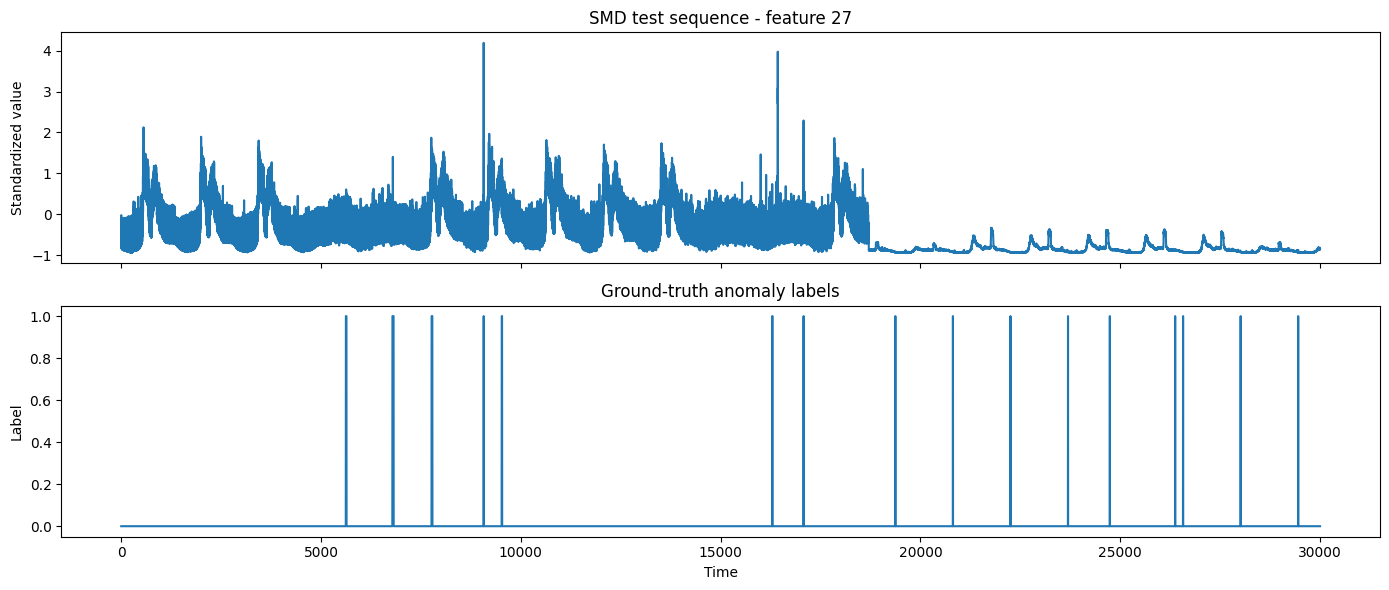

In [7]:
feature = 27
start = 5000
end = 35000

fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

ax[0].plot(test_data[start:end, feature])
ax[0].set_title(f"SMD test sequence - feature {feature}")
ax[0].set_ylabel("Standardized value")

ax[1].plot(test_labels[start:end])
ax[1].set_title("Ground-truth anomaly labels")
ax[1].set_xlabel("Time")
ax[1].set_ylabel("Label")

plt.tight_layout()
plt.show()

## Define the dataset and dataloaders

Each sample is a temporal window with shape:

```text
[sequence length, number of features] = [100, 38]
```

With `step = 100`, the windows do not overlap. This matches the standard SMD configuration used in the Time-Series-Library.

In [8]:
class SMDWindowDataset(Dataset):

    def __init__(self, data, labels, win_size=100, step=100):
        self.data = data
        self.labels = labels
        self.win_size = win_size
        self.step = step

    # number of no overlapping windows.
    def __len__(self):
        return (len(self.data) - self.win_size) // self.step + 1

    # returns the window chosen with the corrispondent sequence in the window
    def __getitem__(self, index):
        start = index * self.step
        end = start + self.win_size

        x = self.data[start:end]
        y = self.labels[start:end]

        return torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)

In [9]:
train_dataset = SMDWindowDataset(
    train_data,
    np.zeros(len(train_data)),
    win_size=seq_len,
    step=step
)

val_dataset = SMDWindowDataset(
    val_data,
    np.zeros(len(val_data)),
    win_size=seq_len,
    step=step
)

test_dataset = SMDWindowDataset(
    test_data,
    test_labels,
    win_size=seq_len,
    step=step
)

pin_memory = torch.cuda.is_available()

train_dataloader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=pin_memory
)

val_dataloader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=pin_memory
)

test_dataloader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=pin_memory
)

print("Train windows:", len(train_dataset))
print("Validation windows:", len(val_dataset))
print("Test windows:", len(test_dataset))

Train windows: 5667
Validation windows: 1416
Test windows: 7084


In [10]:
# Check one batch
batch_x, batch_y = next(iter(train_dataloader))

print("Input batch:", batch_x.shape)
print("Label batch:", batch_y.shape)

Input batch: torch.Size([128, 100, 38])
Label batch: torch.Size([128, 100])


# TimesNet building blocks

For an input tensor:

$$
x \in \mathbb{R}^{B \times T \times N}
$$

`FFT_for_Period` computes the dominant frequencies along the temporal dimension and converts them into periods.

For each selected period, TimesNet reshapes the sequence from:

```text
[B, T, N] - to - [B, N, number of periods, period length]
```

The last two dimensions are processed using 2D convolutions.

In [11]:
def FFT_for_Period(x, k):
    # x shape: [B, T, N]
    xf = torch.fft.rfft(x, dim=1)

    # Average the amplitudes over batch and features
    frequency_list = abs(xf).mean(0).mean(-1)
    frequency_list[0] = 0

    # Select the k dominant frequencies
    _, top_list = torch.topk(frequency_list, k)
    top_list = top_list.detach().cpu().numpy()

    # Convert frequencies into periods
    period = x.shape[1] // top_list

    # Return periods and their amplitudes for each sample
    period_weight = abs(xf).mean(-1)[:, top_list]

    return period, period_weight

## Inception_Block_V1
## 2D Inception Block

The `Inception_Block_V1` is a convolutional module designed to analyze local patterns at different scales simultaneously. Its main idea is inspired by the Inception architecture: instead of applying a single convolution with a fixed kernel size, the block performs several convolutions in parallel using kernels of different sizes.

The kernel sizes are generated according to:

$$
k_i = 2i + 1
$$

where:

$$
i = 0, 1, \dots, \text{num\_kernels}-1
$$

With the default value `num_kernels=6`, the block therefore uses the following kernel sizes:

$$
1 \times 1,\quad
3 \times 3,\quad
5 \times 5,\quad
7 \times 7,\quad
9 \times 9,\quad
11 \times 11
$$

Each convolution receives the same input tensor and produces an output with the same number of channels, specified by `out_channels`. The padding is set to `i`, so that the spatial dimensions of the input are preserved:

$$
H_{\text{out}} = H_{\text{in}},
\qquad
W_{\text{out}} = W_{\text{in}}
$$

The block can be represented schematically as follows:

``` text
        #    -> Conv1 
        # x --> Conv3   -->  average
        #    -> Conv5 
```

The outputs produced by the different convolutions are first collected in a list and then combined using:

```python
res = torch.stack(res_list, dim=-1).mean(-1)
```

`torch.stack` creates a new dimension representing the different convolutional branches. The `mean(-1)` operation then computes the average along this new dimension.

Let (X) be the input tensor and let $(\operatorname{Conv}_{k_i}(X))$ represent the output produced by the convolution with kernel size (k_i). The final output of the block can be written as:

$$
Y =
\frac{1}{K}
\sum_{i=1}^{K}
\operatorname{Conv}_{k_i}(X)
$$

where (K) is the total number of convolutional kernels.

This structure allows the block to combine information extracted from different receptive fields:

* smaller kernels capture fine-grained local patterns;
* larger kernels capture broader structures and longer-range dependencies;
* averaging merges the different representations without increasing the number of output channels.

The convolutional weights are initialized using Kaiming normal initialization:

```python
nn.init.kaiming_normal_(module.weight, mode="fan_out", nonlinearity="relu")
```

This initialization is suitable for layers followed by ReLU-based nonlinearities and helps maintain a stable variance of the activations during training. The convolutional biases are initialized to zero.

Note: this Inception_Block_V1 is the ones used in the Time-Series-Library


In [12]:
class Inception_Block_V1(nn.Module):

    def __init__(self, in_channels, out_channels, num_kernels=6, init_weight=True):
        super().__init__()

        kernels = []

        for i in range(num_kernels):
            kernels.append( nn.Conv2d(in_channels, out_channels, kernel_size=2 * i + 1, padding=i) )

        self.kernels = nn.ModuleList(kernels)

        if init_weight:
            self._initialize_weights()

    def _initialize_weights(self):
        for module in self.modules():
            if isinstance(module, nn.Conv2d):
                nn.init.kaiming_normal_(
                    module.weight,
                    mode="fan_out",
                    nonlinearity="relu"
                )
                if module.bias is not None:
                    nn.init.constant_(module.bias, 0)

    def forward(self, x):
        res_list = []

        # the inception block idea is to implement the convolution in parallel, and
        # then take the average of the convolutions result
        #    -> Conv1 
        # x --> Conv3   -->  media
        #    -> Conv5 

        for kernel in self.kernels:
            res_list.append(kernel(x))

        res = torch.stack(res_list, dim=-1).mean(-1)

        return res

## TimesBlock

The `TimesBlock` is the main building component of TimesNet. Its purpose is to transform a one-dimensional time series into multiple two-dimensional periodic representations, process each representation through a 2D convolutional block, and finally combine the resulting features through an adaptive aggregation mechanism.

Given an input tensor:

```python
x.shape = [B, T, N]
```

where:

* (B) is the batch size;
* (T) is the sequence length;
* (N) is the number of features or hidden channels.

The block first identifies the most relevant periodic patterns in the input sequence using the Fast Fourier Transform.

### Period detection

The following operation extracts the top-(k) dominant periods and their corresponding importance weights:

```python
period_list, period_weight = FFT_for_Period(x, self.k)
```

The FFT converts the input signal from the time domain to the frequency domain. The frequencies with the highest amplitudes are interpreted as the dominant periodic components of the sequence.
For a frequency index (f_i), the corresponding period is approximated as:
$$
p_i = \left\lfloor \frac{T}{f_i} \right\rfloor
$$

where (p_i) represents the (i)-th detected period.
The block processes each of the (k) dominant periods independently.

### Sequence padding

To construct a regular two-dimensional representation, the sequence length must be divisible by the detected period.

Let:

$$
L = \text{seq\_len} + \text{pred\_len}
$$

If (L) is not divisible by the current period (p_i), the padded sequence length is computed as:

$$
L' =
\left(
\left\lfloor \frac{L}{p_i} \right\rfloor + 1
\right)p_i
$$

The number of zero-valued time steps added to the sequence is therefore:

$$
P = L' - L
$$

The padding is appended along the temporal dimension:

```python
out = torch.cat([x, padding], dim=1)
```

This guarantees that the padded sequence can be divided into complete periodic segments.

### From a 1D Sequence to a 2D Periodic Representation

For each detected period (p_i), the input is reshaped from

```text
[B, L', N] to [B, N, L'/p_i, p_i]
```
using:
```python
out = out.reshape(B, length // period, period, N).permute(0, 3, 1, 2).contiguous()
```

The last two dimensions form the 2D temporal representation: (L'/p_i) is the number of periods, while (p_i) is the number of time steps within each period. This allows the block to model both inter-period and intra-period variations.

### Two-dimensional feature extraction

The periodic representation is processed by a convolutional module composed of two Inception blocks and a GELU activation:

```python
self.conv = nn.Sequential(
    Inception_Block_V1(d_model, d_ff, num_kernels=num_kernels),
    nn.GELU(),
    Inception_Block_V1(d_ff, d_model, num_kernels=num_kernels)
)
```

The first Inception block expands the channel dimension from `d_model` to `d_ff`:

$$
d_{\text{model}} \rightarrow d_{\text{ff}}
$$

The GELU activation introduces non-linearity, while the second Inception block projects the representation back to the original hidden dimension:

$$
d_{\text{ff}} \rightarrow d_{\text{model}}
$$

Since each Inception block uses multiple kernel sizes, the model can capture periodic patterns at different spatial and temporal scales.

### Reconstruction of the temporal sequence

After the convolutional processing, the two-dimensional representation is converted back into the original temporal order:

```python
out = out.permute(0, 2, 3, 1).reshape(B, -1, N)
```

The output is then truncated to remove any time steps introduced by padding:

```python
out[:, :self.seq_len + self.pred_len, :]
```

For each detected period, the block therefore produces a tensor with shape:

```text
[B, T, N]
```

The results associated with the (k) dominant periods are collected and stacked along a new dimension:

```python
res = torch.stack(res, dim=-1)
```

The resulting tensor has shape:

```text
[B, T, N, k]
```

### Adaptive aggregation

Not all detected periods contribute equally to the representation. The FFT amplitudes are therefore used to compute an adaptive weight for each period.

The raw period weights are normalized using the softmax function:

$$
\alpha_i =
\frac{\exp(w_i)}
{\sum_{j=1}^{k}\exp(w_j)}
$$

where:

* (w_i) is the raw importance score of the (i)-th period;
* (\alpha_i) is its normalized contribution;
* the normalized weights satisfy:

$$
\sum_{i=1}^{k}\alpha_i = 1
$$

The weights are expanded across the temporal and feature dimensions and applied to the corresponding periodic representations.

The aggregated output is computed as:

$$
Y =
\sum_{i=1}^{k}
\alpha_i Y_i
$$

where (Y_i) is the representation generated using the (i)-th dominant period.

This operation allows the network to assign greater importance to the periodic structures that are more relevant for each input sample.

### Residual connection

Finally, the original input is added to the aggregated representation:

```python
res = res + x
```

The final output can therefore be written as:

$$
Y_{\text{final}}
=

X +
\sum_{i=1}^{k}
\alpha_i Y_i
$$

The residual connection preserves the original temporal information and improves gradient propagation during training.


The main advantage of this block is that it converts complex temporal variations into structured two-dimensional representations. In this way, one spatial dimension models changes within each period, while the other models changes across successive periods.

Note: this is the TimesBlock used in the Time-Series-Library

In [13]:
class TimesBlock(nn.Module):

    def __init__(self, configs):
        super().__init__()

        self.seq_len = configs.seq_len
        self.pred_len = configs.pred_len
        self.k = configs.top_k

        self.conv = nn.Sequential(
            Inception_Block_V1(
                configs.d_model,
                configs.d_ff,
                num_kernels=configs.num_kernels
            ),
            nn.GELU(),
            Inception_Block_V1(
                configs.d_ff,
                configs.d_model,
                num_kernels=configs.num_kernels
            )
        )

    def forward(self, x):
        B, T, N = x.size()

        period_list, period_weight = FFT_for_Period(x, self.k)
        res = []

        for i in range(self.k):
            period = period_list[i]

            # Padding makes the sequence length divisible by the period
            if (self.seq_len + self.pred_len) % period != 0:
                length = ((self.seq_len + self.pred_len) // period + 1) * period

                padding = torch.zeros(B, length - (self.seq_len + self.pred_len), N, device=x.device )

                out = torch.cat([x, padding], dim=1)
            else:
                length = self.seq_len + self.pred_len
                out = x

            # 1D sequence -> periodic 2D representation
            out = out.reshape(
                B,
                length // period,
                period,
                N
            ).permute(0, 3, 1, 2).contiguous()

            out = self.conv(out)

            out = out.permute(0, 2, 3, 1).reshape(B, -1, N)
            res.append(out[:, :self.seq_len + self.pred_len, :])

        res = torch.stack(res, dim=-1)

        # Adaptive aggregation of the k periods
        period_weight = F.softmax(period_weight, dim=1)
        period_weight = period_weight.unsqueeze(1).unsqueeze(1)
        period_weight = period_weight.repeat(1, T, N, 1)

        res = torch.sum(res * period_weight, dim=-1)

        # Residual connection
        res = res + x

        return res

# Non-periodic 1D ablation

Now we start seeing the variants of the original TimesNet.

The non-periodic 1D model removes:

- the FFT;
- the dominant-period selection;
- the periodic 2D reshape;
- the aggregation over different periods.

For this ablation, a custom 1D adaptation of TimesNet's Inception_Block_V1 was introduced by replacing its 2D convolutions with parallel 1D convolutions. Although 1D Inception architectures have previously been proposed for time-series analysis, this implementation specifically preserves the multi-kernel and averaging structure of the original TimesNet block.

Each branch applies a temporal convolution with a different odd kernel size, and the resulting feature maps are combined through an element-wise average. This design provides a controlled comparison with the original 2D TimesBlock while removing its explicit periodic representation.

In [14]:
class Inception_Block_D1(nn.Module):

    def __init__(self, in_channels, out_channels, num_kernels=6, init_weight=True):
        super().__init__()

        kernels = []

        for i in range(num_kernels):
            kernels.append( nn.Conv1d(in_channels, out_channels, kernel_size=2 * i + 1, padding=i) )

        self.kernels = nn.ModuleList(kernels)

        if init_weight:
            self._initialize_weights()

    def _initialize_weights(self):
        for module in self.modules():
            if isinstance(module, nn.Conv1d):
                nn.init.kaiming_normal_(
                    module.weight,
                    mode="fan_out",
                    nonlinearity="relu"
                )
                if module.bias is not None:
                    nn.init.constant_(module.bias, 0)

    def forward(self, x):
        res_list = []

        for kernel in self.kernels:
            res_list.append(kernel(x))

        res = torch.stack(res_list, dim=-1).mean(-1)

        return res

In [15]:
class TimesBlockNoPeriod(nn.Module):

    def __init__(self, configs):
        super().__init__()

        self.conv = nn.Sequential(
            Inception_Block_D1(
                configs.d_model,
                configs.d_ff,
                num_kernels=configs.num_kernels
            ),
            nn.GELU(),
            Inception_Block_D1(
                configs.d_ff,
                configs.d_model,
                num_kernels=configs.num_kernels
            )
        )

    def forward(self, x):
        # [B, T, d_model] -> [B, d_model, T]
        res = x.permute(0, 2, 1)

        # Direct temporal modelling
        res = self.conv(res)

        # [B, d_model, T] -> [B, T, d_model]
        res = res.permute(0, 2, 1)

        # Residual connection
        out = res + x

        return out

# Periodic 1D convolution

Now we build a TimesNet architecture with the idea to use the same organization of the period, but we will use only the 1D relations of the periods.

It means that we will try to catch inter-period relations by using 1D kernels.

This variant keeps the period mechanism of TimesNet while removing its two-dimensional representation. The FFT is still applied to the input sequence to identify the \(k\) dominant periods and to obtain their amplitude-based aggregation weights. However, the sequence is never reshaped into a matrix of shape \([B, N, \text{number of periods}, \text{period length}]\), and no period-dependent padding is required.

The model combines two complementary one-dimensional views of the temporal signal.

First, a local 1D Inception block applies standard convolutions with different odd kernel sizes and dilation equal to one. This branch captures short-range temporal patterns, similarly to the non-periodic 1D ablation.

Second, an inter-period convolution block uses the period \(p_i\) selected by the FFT as the dilation of its 1D convolutions. For example, a kernel of size three with dilation \(p_i\) reads observations at temporal positions \(t-p_i\), \(t\), and \(t+p_i\). A kernel of size five reads \(t-2p_i\), \(t-p_i\), \(t\), \(t+p_i\), and \(t+2p_i\). Therefore, the convolution compares corresponding positions in consecutive cycles without also including all intermediate time steps.

For each selected period \(p_i\), the local and inter-period representations are averaged:

$$
Y_i =
\frac{1}{2}
\left(
Y_{\text{local}} + Y_{\text{inter}}(p_i)
\right)
$$

The representations associated with the \(k\) candidate periods are then aggregated using the softmax-normalized FFT amplitudes, as in the original TimesNet:

$$
Y =
\sum_{i=1}^{k}
\alpha_i Y_i,
\qquad
\sum_{i=1}^{k}\alpha_i = 1
$$

Finally, a residual connection adds the original input to the aggregated representation. This architecture tests whether explicit inter-period relations are useful even without the two-dimensional periodic matrix used by standard TimesNet.

In [16]:
class Inception_Block_D1_InterPeriod(nn.Module):
    def __init__(self, in_channels, out_channels, num_kernels=3, init_weight=True):
        super().__init__()

        self.kernels = nn.ModuleList([
            nn.Conv1d(in_channels, out_channels, kernel_size=2 * i + 1, padding=0)
            for i in range(num_kernels)
        ])

        if init_weight:
            self._initialize_weights()

    def _initialize_weights(self):
        for module in self.modules():
            if isinstance(module, nn.Conv1d):
                nn.init.kaiming_normal_(
                    module.weight,
                    mode="fan_out",
                    nonlinearity="relu"
                )

                if module.bias is not None:
                    nn.init.constant_(module.bias, 0)

    def forward(self, x, period):
        period = int(period)
        outputs = []

        for i, kernel in enumerate(self.kernels):
            # Kernel: 1, 3, 5, ...
            # Dilation: period
            # Padding scelto per preservare T.
            kernel.dilation = (period,)
            kernel.padding = (i * period,)

            outputs.append(kernel(x))

        return torch.stack(outputs, dim=-1).mean(-1)

In [17]:
class InterPeriodConvBlock(nn.Module):
    def __init__(self,d_model,d_ff,num_kernels=3):
        super().__init__()

        self.block_1 = Inception_Block_D1_InterPeriod(d_model, d_ff, num_kernels=num_kernels)
        self.activation = nn.GELU()
        self.block_2 = Inception_Block_D1_InterPeriod(d_ff, d_model, num_kernels=num_kernels)

    def forward(self, x, period):
        x = self.block_1(x, period)
        x = self.activation(x)
        x = self.block_2(x, period)

        return x

In [18]:
class TimesBlock1DwithPeriod(nn.Module):

    def __init__(self, configs):
        super().__init__()

        self.k = configs.top_k

        # Ramo locale: identico alla tua variante 1D senza FFT.
        self.local_conv = nn.Sequential(
            Inception_Block_D1(configs.d_model, configs.d_ff, num_kernels=configs.num_kernels),
            nn.GELU(),
            Inception_Block_D1(configs.d_ff, configs.d_model, num_kernels=configs.num_kernels)
        )

        # Ramo periodico: usa dilation=p per ogni periodo FFT.
        self.inter_conv = InterPeriodConvBlock(configs.d_model, configs.d_ff, num_kernels=3)

    def forward(self, x):
        B, T, N = x.size()

        period_list, period_weight = FFT_for_Period(x, self.k)

        out = x.permute(0, 2, 1).contiguous()

        out_local = self.local_conv(out)
        period_outputs = []

        for period in period_list:
            out_inter = self.inter_conv(out, period)

            out_branch = (out_local + out_inter) / 2
            out_branch = out_branch.permute(0, 2, 1).contiguous()

            period_outputs.append(out_branch)

        # [B, T, d_model, k]
        res = torch.stack(period_outputs, dim=-1)

        period_weight = F.softmax(period_weight, dim=1)
        period_weight = period_weight.unsqueeze(1).unsqueeze(1)
        period_weight = period_weight.expand(-1, T, N, -1)

        res = torch.sum(res * period_weight, dim=-1)

        return res + x

## TimesBlock with Adjusted Padding

## TimesBlock with Adjusted Padding

This version of the `TimesBlock` modifies the construction of the periodic 2D representation following the fractional-period approach proposed in *Improvement of Anomaly Detection Through Enhanced Feature Extraction in TimesNet*.

Instead of approximating each detected period with an integer value, the period is kept as a real-valued quantity:

$$
p_i = \frac{T}{f_i}
$$

where \(T\) is the sequence length and \(f_i\) is the selected frequency index.

For each period \(p_i\), the sequence is divided into successive periodic segments. The boundaries of segment \(j\) are computed as:

$$
h_j = \left\lfloor j p_i + 0.5 \right\rfloor
$$

$$
e_j = \left\lfloor (j+1)p_i + 0.5 \right\rfloor
$$

Because \(p_i\) can be fractional, the resulting segments may have slightly different lengths. To construct a regular 2D representation, every segment is padded to a common width:

$$
\left\lceil p_i \right\rceil
$$

When padding is required, the last observed value of the corresponding segment is repeated until the target width is reached.

The padded segments are then stacked to form the 2D periodic representation processed by the Inception convolutional block. After the convolution, the padding is removed and the original temporal sequence is reconstructed.

In [19]:
def FFT_for_Period_fractional(x, k=2):
    # [B, T, C]
    xf = torch.fft.rfft(x, dim=1) #compute Fourier transform
    # find period by amplitudes
    frequency_list = abs(xf).mean(0).mean(-1)
    
    #remove DC component
    frequency_list[0] = 0

    #top_list has the best indices inside frequency list
    _, top_list = torch.topk(frequency_list, k)
    top_list = top_list.detach().cpu().numpy() #convert in numpy array
    
    # sequence length / frequency index
    period = x.shape[1] / top_list

    # return period and period weight
    return period, abs(xf).mean(-1)[:, top_list], top_list

class TimesBlockFractional(nn.Module):
    def __init__(self, configs):
        super(TimesBlockFractional, self).__init__()

        self.seq_len = configs.seq_len
        self.pred_len = configs.pred_len
        self.k = configs.top_k

        # as before
        self.conv = nn.Sequential(
            Inception_Block_V1(configs.d_model, configs.d_ff,
                               num_kernels=configs.num_kernels),
            nn.GELU(),
            Inception_Block_V1(configs.d_ff, configs.d_model,
                               num_kernels=configs.num_kernels)
        )

        print("init Fractional timesBlock")

    def forward(self, x):
        B, T, N = x.size()

        period_list, period_weight, freq_list = FFT_for_Period_fractional(x, self.k)
        res = []

        for i in range(self.k):
            # Fractional period associated with the i-th selected frequency.
            period = float(period_list[i])

            # Number of periods contained in the input sequence.
            frequency = int(freq_list[i])
            # Common width used for all segments.
            ceil_period = math.ceil(period)

            segments = []
            segment_lengths = []

            for j in range(frequency):
                head = math.floor(j * period + 0.5)
                end = math.floor((j + 1) * period + 0.5)

                # Defensive clipping to the original sequence.
                head = min(head, T)
                end = min(end, T)

                # Shape: [B, segment_length, N]
                current_segment = x[:, head:end, :]

                segment_length = current_segment.shape[1]
                segment_lengths.append(segment_length)

                missing = ceil_period - segment_length

                if missing > 0:
                    # Method 2: identical-value padding.
                    last_value = current_segment[:, -1:, :]

                    padding = last_value.repeat(1, missing, 1)
                    current_segment = torch.cat([current_segment, padding], dim=1)

                elif missing < 0:
                    # Defensive case: trim an unexpectedly long segment.
                    current_segment = current_segment[:, :ceil_period, :]

                segments.append(current_segment)

            # Each segment now has shape [B, ceil_period, N].
            # Result: [B, frequency, ceil_period, N]
            out = torch.stack(segments, dim=1)

            # Conv2d expects channels in the second dimension.
            # Result: [B, N, frequency, ceil_period]
            out = out.permute(0, 3, 1, 2).contiguous()

            # Continue with the Inception block.
            out = self.conv(out)

            # Restore time/channel ordering.
            out = out.permute(0, 2, 3, 1).contiguous()

            # we need to remove the padding
            valid_out_segments = []
            for j in range(frequency):
                l = segment_lengths[j]

                valid_segment = out[:, j, :l, :]
                valid_out_segments.append(valid_segment)

            out = torch.cat(valid_out_segments, dim=1)

            # Assicuriamoci che la lunghezza finale sia esattamente T
            if out.shape[1] > T:
                out = out[:, :T, :]
            elif out.shape[1] < T:
                pad_missing = T - out.shape[1]
                final_pad = torch.zeros(B, pad_missing, N, device=x.device, dtype=x.dtype)
                out = torch.cat([out, final_pad], dim=1)

            res.append(out)

        res = torch.stack(res, dim=-1)

        period_weight = F.softmax(period_weight, dim=1)

        period_weight = period_weight.unsqueeze(1).unsqueeze(1)
        period_weight = period_weight.repeat(1, T, N, 1)

        res = torch.sum(res * period_weight, dim=-1)
        res = res + x

        return res


# TimesNet model for anomaly detection

The model is trained as an autoencoder:

```text
input window -> TimesNet -> reconstructed window
```

Training uses only normal SMD data and minimizes the mean squared reconstruction error.

### Input Data Embedding

This embedding module follows the input-embedding structure used in the original TimesNet implementation that I found at https://github.com/thuml/Time-Series-Library/blob/main/layers/Embed.py. Before entering the TimesBlocks, the multivariate input sequence is projected into a latent space of dimension `d_model` and enriched with positional information.

Given an input tensor with shape:

```text
[B, T, C]
```

where (B) is the batch size, (T) is the sequence length, and (C) is the number of input variables, the embedding layer produces:

```text
[B, T, d_model]
```

#### Token Embedding

The `TokenEmbedding` projects the original variables from `c_in` channels to `d_model` hidden channels using a one-dimensional convolution:

```python
self.token_conv = nn.Conv1d(c_in, d_model, kernel_size=3, padding=1, padding_mode="circular", bias=False)
```

Since `Conv1d` expects the channel dimension before the temporal dimension, the input is temporarily rearranged from `[B, T, C]` to `[B, C, T]`.

The convolution uses a kernel size of three, allowing each embedded time step to incorporate information from its neighbouring observations. Circular padding preserves the sequence length by treating the sequence boundaries as connected.

#### Positional Embedding

The `PositionalEmbedding` adds information about the temporal position of each observation. It uses the fixed sinusoidal encoding introduced for Transformer models:

$$
PE(pos, 2i)
=

\sin
\left(
\frac{pos}{10000^{2i/d_{\text{model}}}}
\right)
$$

$$
PE(pos, 2i+1)
=

\cos
\left(
\frac{pos}{10000^{2i/d_{\text{model}}}}
\right)
$$

where (pos) is the temporal position and (i) identifies the embedding dimension.

The positional matrix is registered as a buffer:

```python
self.register_buffer("pe", pe)
```

Therefore, it is stored with the model and moved automatically between devices, but it is not updated during training.

#### Combined Data Embedding

The final representation is obtained by adding the value and positional embeddings:

$$
E(X)
=

E_{\text{value}}(X)
+
E_{\text{position}}(X)
$$

Dropout is then applied:

```python
x = self.value_embedding(x) + self.position_embedding(x)
return self.dropout(x)
```

The resulting tensor preserves the temporal length of the input while replacing the original feature dimension with `d_model`. It therefore provides TimesNet with both a learned representation of the input values and explicit information about their temporal positions.


In [20]:
class PositionalEmbedding(nn.Module):

    def __init__(self, d_model, max_len=5000):
        super().__init__()

        position = torch.arange(max_len).float().unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2).float()
            * (-np.log(10000.0) / d_model)
        )

        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        pe = pe.unsqueeze(0)
        self.register_buffer("pe", pe)

    def forward(self, x):
        return self.pe[:, :x.size(1)]


class TokenEmbedding(nn.Module):

    def __init__(self, c_in, d_model):
        super().__init__()

        self.token_conv = nn.Conv1d(
            c_in,
            d_model,
            kernel_size=3,
            padding=1,
            padding_mode="circular",
            bias=False
        )

        nn.init.kaiming_normal_(
            self.token_conv.weight,
            mode="fan_in",
            nonlinearity="leaky_relu"
        )

    def forward(self, x):
        x = self.token_conv(x.permute(0, 2, 1))
        return x.transpose(1, 2)


class DataEmbedding(nn.Module):

    def __init__(self, c_in, d_model, dropout=0.1):
        super().__init__()

        self.value_embedding = TokenEmbedding(c_in, d_model)
        self.position_embedding = PositionalEmbedding(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        x = self.value_embedding(x) + self.position_embedding(x)
        return self.dropout(x)

## TimesNet Model for Anomaly Detection

The `TimesNet` class defines the complete reconstruction model used for anomaly detection. Its architecture follows the original TimesNet processing pipeline, while allowing the user to choose between the standard periodic `TimesBlock` and all the other variants.

The model receives an input tensor with shape:

```text
[B, T, C]
```

where (B) is the batch size, (T) is the sequence length, and (C) is the number of input variables. Its objective is to reconstruct a sequence with the same temporal and feature dimensions.

### Block selection

The architecture can use two alternative processing blocks:

```python
if configs.block_type == 0:
    block = TimesBlockNoPeriod
elif configs.block_type == 1:
    block = TimesBlock1dwithPeriod
elif configs.block_type == 2:
    block = TimesBlock
else:
    block = TimesBlockFractional
```

The selected TimesBlock is repeated `e_layers` times.

### Input normalization

Before the embedding stage, each sample is normalized independently along the temporal dimension.


The mean is detached from the computational graph.
This normalization reduces the effect of different feature scales and changing temporal distributions.

### Embedding

The normalized input is projected from the original feature dimension `enc_in` to the latent dimension `d_model`.
The embedding combines convolutional value information with sinusoidal positional information, as we have seen before.

### Stacked TimesNet blocks

The embedded representation is processed by the selected TimesNet blocks:

```python
for i in range(self.layer):
    enc_out = self.layer_norm(self.model[i](enc_out))
```

After each block, layer normalization is applied:

$$
H^{(l)}
=

\operatorname{LayerNorm}
\left(
\operatorname{Block}^{(l)}
\left(H^{(l-1)}\right)
\right)
$$

Layer normalization stabilizes the hidden representation and helps maintain consistent activation scales across the stacked blocks.

### Output projection

The final hidden representation is projected back to the original feature space:

```python
dec_out = self.projection(enc_out)
```

The projection performs:

$$
\mathbb{R}^{d_{\text{model}}}
\rightarrow
\mathbb{R}^{c_{\text{out}}}
$$

For reconstruction-based anomaly detection, `c_out` normally corresponds to the number of original input variables.

### De-normalization

The reconstructed sequence is returned to its original scale using the previously computed standard deviation and mean:

$$
\hat{X}
=

\hat{X}^{norm}\odot\sigma+\mu
$$

This is implemented as:

```python
dec_out = dec_out * stdev
dec_out = dec_out + means
```

The final output has shape:

```text
[B, T, c_out]
```

and represents the reconstruction of the original input sequence.

During anomaly detection, the reconstruction error between the input (X) and the output $\hat{X}$ can be used as an anomaly score:

$$
s_{b,t}
=

\frac{1}{C}
\sum_{c=1}^{C}
\left(
x_{b,t,c}-\hat{x}_{b,t,c}
\right)^2
$$

Time steps with high reconstruction error are more likely to correspond to anomalous observations.


The normalization, embedding, stacked-block processing, projection, and de-normalization stages follow the original TimesNet anomaly-detection structure. The configurable selection between the periodic and non-periodic block is introduced to support the proposed ablation study.


In [21]:
class TimesNet(nn.Module):

    def __init__(self, configs):
        super().__init__()

        self.configs = configs
        self.seq_len = configs.seq_len
        self.pred_len = configs.pred_len
        self.layer = configs.e_layers

        if configs.block_type == 0:
            block = TimesBlockNoPeriod
        elif configs.block_type == 1:
            block = TimesBlock1DwithPeriod
        elif configs.block_type == 2:
            block = TimesBlock
        elif configs.block_type == 3:
            block = TimesBlockFractional

        self.model = nn.ModuleList([
            block(configs) for _ in range(configs.e_layers)
        ])

        self.enc_embedding = DataEmbedding(
            configs.enc_in,
            configs.d_model,
            configs.dropout
        )

        self.layer_norm = nn.LayerNorm(configs.d_model)
        self.projection = nn.Linear(
            configs.d_model,
            configs.c_out
        )

    def anomaly_detection(self, x_enc):
        # Normalization used by the TimesNet implementation
        means = x_enc.mean(1, keepdim=True).detach()
        x_enc = x_enc - means

        stdev = torch.sqrt(
            torch.var(
                x_enc,
                dim=1,
                keepdim=True,
                unbiased=False
            ) + 1e-5
        )

        x_enc = x_enc / stdev
        enc_out = self.enc_embedding(x_enc)

        # TimesNet blocks
        for i in range(self.layer):
            enc_out = self.layer_norm(self.model[i](enc_out))

        dec_out = self.projection(enc_out)

        dec_out = dec_out * stdev
        dec_out = dec_out + means

        return dec_out

    def forward(self, x):
        return self.anomaly_detection(x)

In [22]:
def make_configs(block_type):
    return SimpleNamespace(
        seq_len=seq_len,
        pred_len=0,
        top_k=top_k,
        num_kernels=num_kernels,
        d_model=d_model,
        d_ff=d_ff,
        e_layers=e_layers,
        enc_in=n_features_train,
        c_out=n_features_train,
        dropout=dropout,
        block_type=block_type
    )


def count_parameters(model):
    return sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )


# Check the output shape of both models
model_1d_test_noPeriod = TimesNet(make_configs(block_type=0))
model_1d_test_withPeriod = TimesNet(make_configs(block_type=1))
model_2d_test = TimesNet(make_configs(block_type=2))
model_2dFractional_test = TimesNet(make_configs(block_type=3))

sample_x = batch_x[:2]

with torch.no_grad():
    output_1d = model_1d_test_noPeriod(sample_x)
    output_1d_period = model_1d_test_withPeriod(sample_x)
    output_2d = model_2d_test(sample_x)
    output_2dFractional = model_2dFractional_test(sample_x)

print("Input shape:", sample_x.shape)
print("1D output shape:", output_1d.shape)
print("1D_period output shape:", output_1d.shape)
print("2D output shape:", output_2d.shape)
print("2D_fractional output shape:", output_2dFractional.shape)
print("1D parameters:", f"{count_parameters(model_1d_test_noPeriod):,}")
print("2D parameters:", f"{count_parameters(model_2d_test):,}")

init Fractional timesBlock
init Fractional timesBlock
init Fractional timesBlock
Input shape: torch.Size([2, 100, 38])
1D output shape: torch.Size([2, 100, 38])
1D_period output shape: torch.Size([2, 100, 38])
2D output shape: torch.Size([2, 100, 38])
2D_fractional output shape: torch.Size([2, 100, 38])
1D parameters: 896,934
2D parameters: 7,040,934


# Training

The training procedure follows the anomaly-detection experiment:

- reconstruction loss: MSE;
- optimizer: Adam;
- initial learning rate: `1e-4`;
- learning rate divided by two after each epoch;
- early stopping based on validation reconstruction loss;
- best model saved in the `checkpoints_notebook` folder.

In [23]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)


def train_epoch(model, dataloader, loss_fn, optimizer):
    model.train()
    losses = []

    for batch_x, _ in dataloader:
        batch_x = batch_x.to(device)

        output = model(batch_x)
        loss = loss_fn(output, batch_x)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        losses.append(loss.item())

    return np.mean(losses)


def validation_epoch(model, dataloader, loss_fn):
    model.eval()
    losses = []

    with torch.no_grad():
        for batch_x, _ in dataloader:
            batch_x = batch_x.to(device)

            output = model(batch_x)
            loss = loss_fn(output, batch_x)

            losses.append(loss.item())

    return np.mean(losses)

In [24]:
def train_model(block_type, seed, model_name):
    set_seed(seed)

    model = TimesNet(make_configs(block_type)).to(device)

    loss_fn = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.5)

    checkpoint_dir = Path("./checkpoints_notebook")
    checkpoint_dir.mkdir(exist_ok=True)

    checkpoint_path = checkpoint_dir / f"{model_name}_seed_{seed}.pth"

    best_val_loss = np.inf
    early_stopping_counter = 0
    history = []

    start_training = time.time()

    for epoch in range(train_epochs):
        start_epoch = time.time()

        train_loss = train_epoch(model, train_dataloader, loss_fn, optimizer)

        val_loss = validation_epoch(model, val_dataloader, loss_fn)

        # test_loss = validation_epoch(model, test_dataloader, loss_fn)

        epoch_time = time.time() - start_epoch

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss,
            # "test_loss": test_loss,
            "learning_rate": optimizer.param_groups[0]["lr"],
            "epoch_time": epoch_time
        })

        print(
            f"Epoch: {epoch + 1}, "
            f"Train Loss: {train_loss:.7f}, "
            f"Vali Loss: {val_loss:.7f}, "
            # f"Test Loss: {test_loss:.7f}, "
            f"Time: {epoch_time:.2f}s"
        )

        if val_loss < best_val_loss:
            print("Validation loss decreased. Saving model ...")
            torch.save(model.state_dict(), checkpoint_path)
            best_val_loss = val_loss
            early_stopping_counter = 0
        else:
            early_stopping_counter += 1
            print(
                f"EarlyStopping counter: "
                f"{early_stopping_counter} out of {patience}"
            )

        if early_stopping_counter >= patience:
            print("Early stopping")
            break

        print("Learning rate", optimizer.param_groups[0]["lr"])
        scheduler.step()

    training_time = time.time() - start_training

    model.load_state_dict(
        torch.load(checkpoint_path, map_location=device)
    )

    history = pd.DataFrame(history)

    return model, history, training_time

## Train the non-periodic 1D model

`dim = 0` selects `TimesBlockNoPeriod`.

In [25]:
model_1d, history_1d, training_time_1d = train_model(
    block_type=0,
    seed=seed,
    model_name="TimesNet_1D_noPeriod"
)

Epoch: 1, Train Loss: 0.2734513, Vali Loss: 0.3876106, Time: 3.52s
Validation loss decreased. Saving model ...
Learning rate 0.0001
Epoch: 2, Train Loss: 0.2303498, Vali Loss: 0.3609862, Time: 1.92s
Validation loss decreased. Saving model ...
Learning rate 5e-05
Epoch: 3, Train Loss: 0.2173286, Vali Loss: 0.3487063, Time: 1.92s
Validation loss decreased. Saving model ...
Learning rate 2.5e-05
Epoch: 4, Train Loss: 0.2106079, Vali Loss: 0.3423663, Time: 1.91s
Validation loss decreased. Saving model ...
Learning rate 1.25e-05
Epoch: 5, Train Loss: 0.2145996, Vali Loss: 0.3393116, Time: 1.91s
Validation loss decreased. Saving model ...
Learning rate 6.25e-06
Epoch: 6, Train Loss: 0.2208406, Vali Loss: 0.3377445, Time: 1.93s
Validation loss decreased. Saving model ...
Learning rate 3.125e-06
Epoch: 7, Train Loss: 0.2078533, Vali Loss: 0.3369355, Time: 1.90s
Validation loss decreased. Saving model ...
Learning rate 1.5625e-06
Epoch: 8, Train Loss: 0.2074070, Vali Loss: 0.3365347, Time: 1.93

## Train the periodic 1D model

`dim = 1` selects `TimesBlock1dwithPeriod`.

In [26]:
model_1d_period, history_1d_period, training_time_1d_period = train_model(
    block_type=1,
    seed=seed,
    model_name="TimesNet_1D_withPeriod"
)

Epoch: 1, Train Loss: 0.2751266, Vali Loss: 0.2975541, Time: 4.58s
Validation loss decreased. Saving model ...
Learning rate 0.0001
Epoch: 2, Train Loss: 0.2412496, Vali Loss: 0.2754055, Time: 3.43s
Validation loss decreased. Saving model ...
Learning rate 5e-05
Epoch: 3, Train Loss: 0.2276224, Vali Loss: 0.2648185, Time: 3.46s
Validation loss decreased. Saving model ...
Learning rate 2.5e-05
Epoch: 4, Train Loss: 0.2257681, Vali Loss: 0.2598709, Time: 3.43s
Validation loss decreased. Saving model ...
Learning rate 1.25e-05
Epoch: 5, Train Loss: 0.2175798, Vali Loss: 0.2573455, Time: 3.43s
Validation loss decreased. Saving model ...
Learning rate 6.25e-06
Epoch: 6, Train Loss: 0.2172536, Vali Loss: 0.2560775, Time: 3.41s
Validation loss decreased. Saving model ...
Learning rate 3.125e-06
Epoch: 7, Train Loss: 0.2163265, Vali Loss: 0.2554706, Time: 3.44s
Validation loss decreased. Saving model ...
Learning rate 1.5625e-06
Epoch: 8, Train Loss: 0.2162689, Vali Loss: 0.2551487, Time: 3.43

## Train the periodic 2D model

`dim = 2` selects the original periodic `TimesBlock`.

In [27]:
model_2d, history_2d, training_time_2d = train_model(
    block_type=2,
    seed=seed,
    model_name="TimesNet_2D"
)

Epoch: 1, Train Loss: 0.2914410, Vali Loss: 0.2868116, Time: 14.41s
Validation loss decreased. Saving model ...
Learning rate 0.0001
Epoch: 2, Train Loss: 0.2467491, Vali Loss: 0.2700387, Time: 14.31s
Validation loss decreased. Saving model ...
Learning rate 5e-05
Epoch: 3, Train Loss: 0.2281811, Vali Loss: 0.2621761, Time: 14.30s
Validation loss decreased. Saving model ...
Learning rate 2.5e-05
Epoch: 4, Train Loss: 0.2201195, Vali Loss: 0.2582181, Time: 14.31s
Validation loss decreased. Saving model ...
Learning rate 1.25e-05
Epoch: 5, Train Loss: 0.2187909, Vali Loss: 0.2563476, Time: 14.36s
Validation loss decreased. Saving model ...
Learning rate 6.25e-06
Epoch: 6, Train Loss: 0.2140029, Vali Loss: 0.2553829, Time: 14.36s
Validation loss decreased. Saving model ...
Learning rate 3.125e-06
Epoch: 7, Train Loss: 0.2149452, Vali Loss: 0.2549117, Time: 14.45s
Validation loss decreased. Saving model ...
Learning rate 1.5625e-06
Epoch: 8, Train Loss: 0.2139424, Vali Loss: 0.2546549, Tim

## Train the 2D model with internal padding and identical value

`dim = 3` selects the fractional periodic `TimesBlockFractional`.

In [28]:
model_2d_frac, history_2d_frac, training_time_2d_frac = train_model(
    block_type=3,
    seed=seed,
    model_name="TimesNet_2D_Fractional"
)

init Fractional timesBlock
init Fractional timesBlock
init Fractional timesBlock
Epoch: 1, Train Loss: 0.2914733, Vali Loss: 0.2869727, Time: 13.48s
Validation loss decreased. Saving model ...
Learning rate 0.0001
Epoch: 2, Train Loss: 0.2468643, Vali Loss: 0.2701250, Time: 13.45s
Validation loss decreased. Saving model ...
Learning rate 5e-05
Epoch: 3, Train Loss: 0.2282796, Vali Loss: 0.2622835, Time: 13.50s
Validation loss decreased. Saving model ...
Learning rate 2.5e-05
Epoch: 4, Train Loss: 0.2202000, Vali Loss: 0.2582404, Time: 13.51s
Validation loss decreased. Saving model ...
Learning rate 1.25e-05
Epoch: 5, Train Loss: 0.2188682, Vali Loss: 0.2563487, Time: 13.47s
Validation loss decreased. Saving model ...
Learning rate 6.25e-06
Epoch: 6, Train Loss: 0.2140762, Vali Loss: 0.2553772, Time: 13.41s
Validation loss decreased. Saving model ...
Learning rate 3.125e-06
Epoch: 7, Train Loss: 0.2150169, Vali Loss: 0.2548977, Time: 13.43s
Validation loss decreased. Saving model ...
Le

In [29]:
print("1D epochs:", len(history_1d))
print("1D_Period epochs:", len(history_1d_period))
print("2D epochs:", len(history_2d))
print("2D_Fractional epochs:", len(history_2d_frac))

print("2D validation history:")
for epoch, loss in enumerate(history_2d, start=1):
    print(epoch, loss)

1D epochs: 10
1D_Period epochs: 10
2D epochs: 10
2D_Fractional epochs: 10
2D validation history:
1 epoch
2 train_loss
3 val_loss
4 learning_rate
5 epoch_time


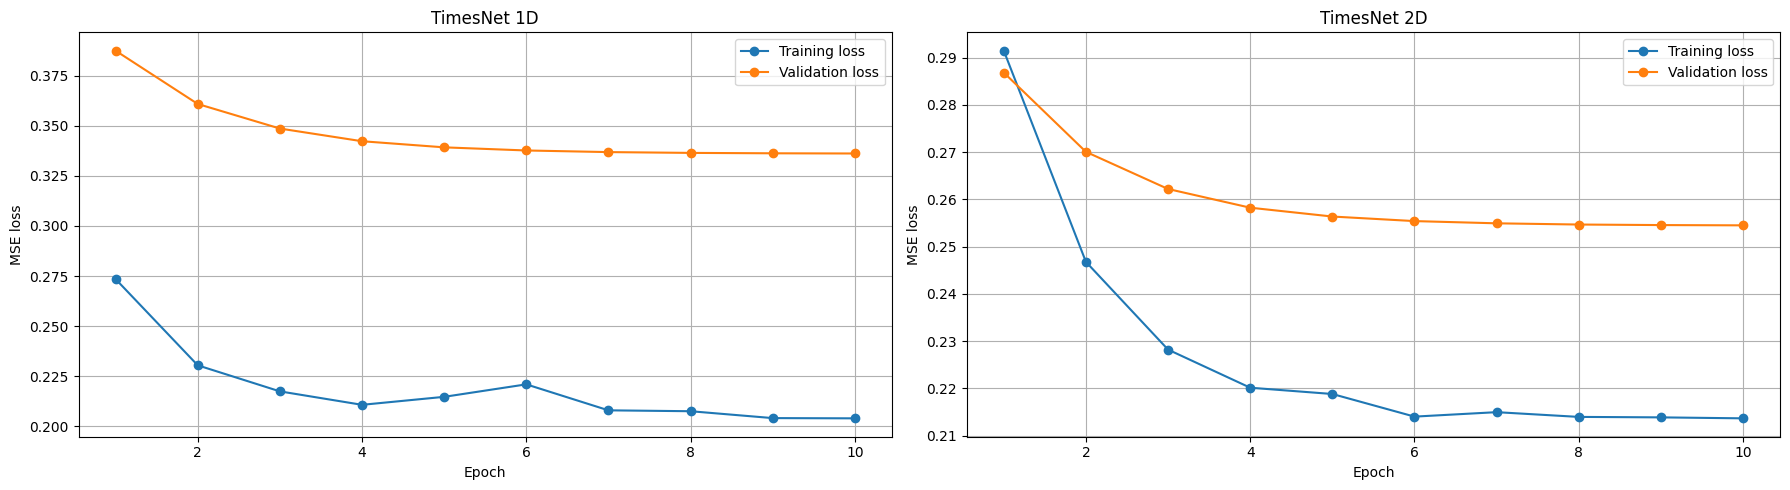

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# 1D model
axes[0].plot(
    history_1d["epoch"],
    history_1d["train_loss"],
    marker="o",
    label="Training loss"
)

axes[0].plot(
    history_1d["epoch"],
    history_1d["val_loss"],
    marker="o",
    label="Validation loss"
)

axes[0].set_title("TimesNet 1D")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE loss")
axes[0].legend()
axes[0].grid()

# 2D model
axes[1].plot(
    history_2d["epoch"],
    history_2d["train_loss"],
    marker="o",
    label="Training loss"
)

axes[1].plot(
    history_2d["epoch"],
    history_2d["val_loss"],
    marker="o",
    label="Validation loss"
)

axes[1].set_title("TimesNet 2D")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MSE loss")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

# Anomaly Detection

TimesNet is trained as a reconstruction model. For each input window, the model receives a multivariate sequence and attempts to reproduce the same observations at its output.

Let the input tensor for one window be:

$$
X \in \mathbb{R}^{T \times N}
$$

where \(T\) is the number of time steps in the window and \(N\) is the number of features. The model produces the reconstruction:

$$
\hat{X} \in \mathbb{R}^{T \times N}
$$

For each time step \(t\) and feature \(n\), the feature-level reconstruction error is:

$$
e_{t,n}
=
\left(
x_{t,n}-\hat{x}_{t,n}
\right)^2
$$

The anomaly energy at time \(t\) is then computed as the mean squared reconstruction error across all features:

$$
E_t
=
\frac{1}{N}
\sum_{n=1}^{N}
\left(
x_{t,n}-\hat{x}_{t,n}
\right)^2
$$

In the implementation, this corresponds to:

```python
loss_fn = nn.MSELoss(reduction="none")
score = torch.mean(loss_fn(batch_x, output), dim=-1)
```

In [31]:
def get_anomaly_energy(model, dataloader):
    model.eval()

    energies = []
    labels = []
    loss_fn = nn.MSELoss(reduction="none")

    with torch.no_grad():
        for batch_x, batch_y in dataloader:
            batch_x = batch_x.to(device)

            output = model(batch_x)

            # Mean reconstruction error over the feature dimension
            score = torch.mean(loss_fn(batch_x, output), dim=-1)

            energies.append(score.cpu().numpy())
            labels.append(batch_y.numpy())

    energies = np.concatenate(energies, axis=0).reshape(-1)
    labels = np.concatenate(labels, axis=0).reshape(-1)

    return energies, labels


def adjustment(gt, pred):
    # Event-level adjustment used by the anomaly-detection experiment
    anomaly_state = False

    for i in range(len(gt)):
        if gt[i] == 1 and pred[i] == 1 and not anomaly_state:
            anomaly_state = True

            for j in range(i, -1, -1):
                if gt[j] == 0:
                    break
                pred[j] = 1

            for j in range(i, len(gt)):
                if gt[j] == 0:
                    break
                pred[j] = 1

        elif gt[i] == 0:
            anomaly_state = False

        if anomaly_state:
            pred[i] = 1

    return gt, pred

In [32]:
def compute_metrics(gt, pred):
    accuracy = accuracy_score(gt, pred)

    precision, recall, f1, _ = precision_recall_fscore_support(
        gt,
        pred,
        average="binary",
        zero_division=0
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }


def evaluate_model(model, model_name, training_time):
    train_energy, _ = get_anomaly_energy(model,train_dataloader)
    val_energy, _ = get_anomaly_energy(model, val_dataloader)
    test_energy, gt = get_anomaly_energy(model, test_dataloader)

    combined_energy = np.concatenate([train_energy, val_energy])

    threshold = np.percentile(combined_energy, 100 - anomaly_ratio)

    pred_raw = (test_energy > threshold).astype(int)
    raw_metrics = compute_metrics(gt, pred_raw)

    gt_adjusted, pred_adjusted = adjustment(
        gt.copy().astype(int),
        pred_raw.copy()
    )

    adjusted_metrics = compute_metrics(gt_adjusted, pred_adjusted)

    result = {
        "model": model_name,
        "parameters": count_parameters(model),
        "training_time": training_time,
        "threshold": threshold,
        "raw_accuracy": raw_metrics["accuracy"],
        "raw_precision": raw_metrics["precision"],
        "raw_recall": raw_metrics["recall"],
        "raw_f1": raw_metrics["f1"],
        "accuracy": adjusted_metrics["accuracy"],
        "precision": adjusted_metrics["precision"],
        "recall": adjusted_metrics["recall"],
        "f1": adjusted_metrics["f1"]
    }

    print("Threshold:", threshold)
    print(
        "Adjusted metrics - "
        f"Accuracy: {adjusted_metrics['accuracy']:.4f}, "
        f"Precision: {adjusted_metrics['precision']:.4f}, "
        f"Recall: {adjusted_metrics['recall']:.4f}, "
        f"F1: {adjusted_metrics['f1']:.4f}"
    )

    return result, test_energy, gt, pred_raw, pred_adjusted

## Evaluate the four methods models

In [33]:
result_1d, energy_1d, gt_1d, pred_raw_1d, pred_1d = evaluate_model(
    model_1d,
    model_name="TimesNet 1D - no periodicity",
    training_time=training_time_1d
)

Threshold: 3.876134
Adjusted metrics - Accuracy: 0.9849, Precision: 0.8314, Recall: 0.7997, F1: 0.8152


In [34]:
result_1d_period, energy_1d_period, gt_1d_period, pred_raw_1d_period, pred_1d_period = evaluate_model(
    model_1d_period,
    model_name="TimesNet 1D - periodicity",
    training_time=training_time_1d_period
)

Threshold: 2.983636
Adjusted metrics - Accuracy: 0.9844, Precision: 0.7997, Recall: 0.8328, F1: 0.8159


In [35]:
result_2d, energy_2d, gt_2d, pred_raw_2d, pred_2d = evaluate_model(
    model_2d,
    model_name="TimesNet 2D - periodic",
    training_time=training_time_2d
)

Threshold: 3.0823464
Adjusted metrics - Accuracy: 0.9851, Precision: 0.8113, Recall: 0.8360, F1: 0.8235


In [36]:
result_2d_frac, energy_2d_frac, gt_2d_frac, pred_raw_2d_frac, pred_2d_frac = evaluate_model(
    model_2d_frac,
    model_name="TimesNet 2D - fractional",
    training_time=training_time_2d_frac
)

Threshold: 3.0820782
Adjusted metrics - Accuracy: 0.9851, Precision: 0.8110, Recall: 0.8360, F1: 0.8233


In [37]:
results = pd.DataFrame([
    result_1d,
    result_1d_period,
    result_2d,
    result_2d_frac
])

display(results)

results.to_csv(
    "timesnet_1d_vs_2d_results.csv",
    index=False
)

,model,parameters,training_time,threshold,raw_accuracy,raw_precision,raw_recall,raw_f1,accuracy,precision,recall,f1
0,TimesNet 1D - no periodicity,896934,20.959459,3.876134,0.954145,0.266370,0.058857,0.096412,0.984935,0.831450,0.799654,0.815242
1,TimesNet 1D - periodicity,1119270,35.679142,2.983636,0.952804,0.259407,0.073054,0.114003,0.984380,0.799713,0.832767,0.815905
2,TimesNet 2D - periodic,7040934,144.233097,3.082346,0.953300,0.267093,0.070846,0.111988,0.985103,0.811332,0.835994,0.823478
3,TimesNet 2D - fractional,7040934,135.260228,3.082078,0.953303,0.267994,0.071322,0.112661,0.985086,0.811011,0.835994,0.823313


# Visualize the anomaly scores

Change `start` and `end` to inspect a different portion of the test sequence.

In [38]:
np.where(gt_1d == 1)[0][:20]

array([10620, 10621, 10622, 10623, 10624, 10625, 10626, 10627, 10628,
       10629, 10630, 10631, 10632, 10633, 10634, 10635, 10636, 11785,
       11786, 11787])

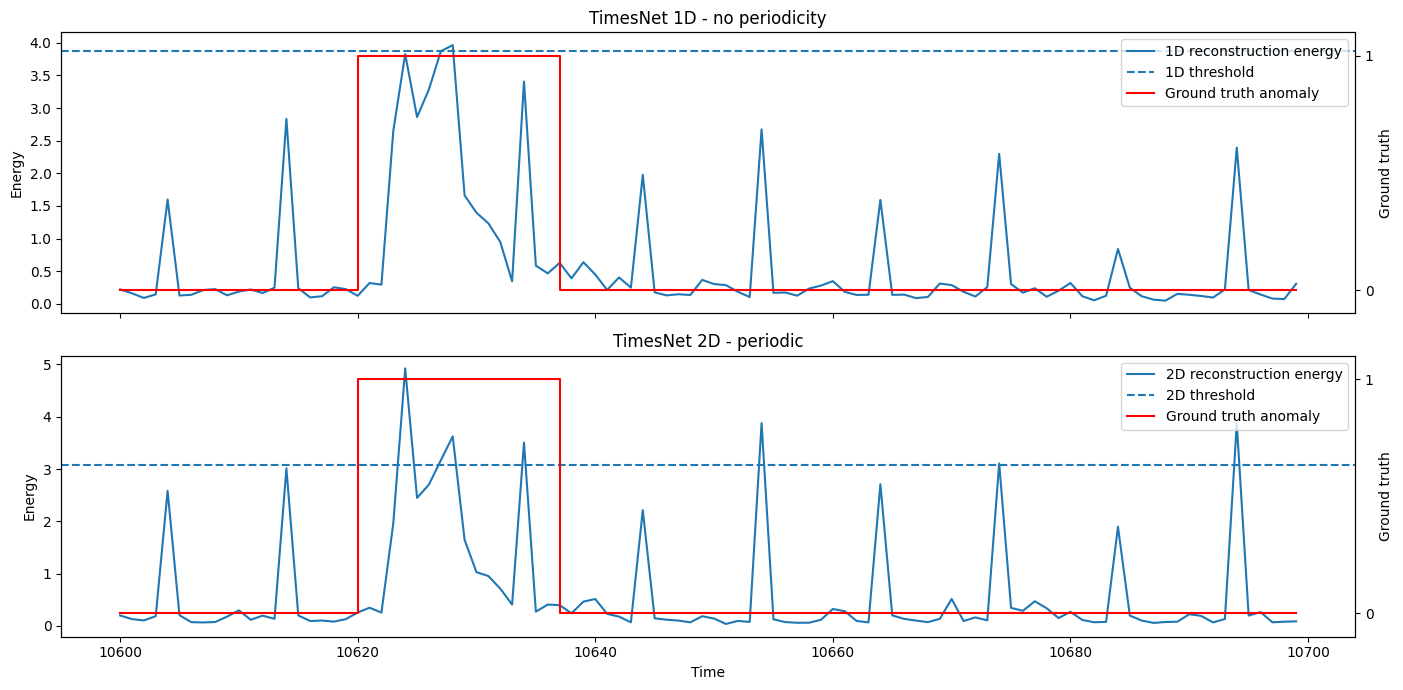

1D unique labels: (array([0., 1.], dtype=float32), array([83, 17]))
2D unique labels: (array([0., 1.], dtype=float32), array([83, 17]))


In [39]:
start = 10600
end = 10700
x = np.arange(start, end)

fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

# ---------- 1D ----------
ax[0].plot(x, energy_1d[start:end], label="1D reconstruction energy")
ax[0].axhline(
    result_1d["threshold"],
    linestyle="--",
    label="1D threshold"
)
ax[0].set_title("TimesNet 1D - no periodicity")
ax[0].set_ylabel("Energy")

ax0_gt = ax[0].twinx()
ax0_gt.step(
    x,
    gt_1d[start:end],
    where="post",
    color="red",
    label="Ground truth anomaly"
)
ax0_gt.set_ylabel("Ground truth")
ax0_gt.set_ylim(-0.1, 1.1)
ax0_gt.set_yticks([0, 1])

lines1, labels1 = ax[0].get_legend_handles_labels()
lines2, labels2 = ax0_gt.get_legend_handles_labels()
ax[0].legend(lines1 + lines2, labels1 + labels2, loc="upper right")

# ---------- 2D ----------
ax[1].plot(x, energy_2d[start:end], label="2D reconstruction energy")
ax[1].axhline(
    result_2d["threshold"],
    linestyle="--",
    label="2D threshold"
)
ax[1].set_title("TimesNet 2D - periodic")
ax[1].set_xlabel("Time")
ax[1].set_ylabel("Energy")

ax1_gt = ax[1].twinx()
ax1_gt.step(
    x,
    gt_2d[start:end],
    where="post",
    color="red",
    label="Ground truth anomaly"
)
ax1_gt.set_ylabel("Ground truth")
ax1_gt.set_ylim(-0.1, 1.1)
ax1_gt.set_yticks([0, 1])

lines1, labels1 = ax[1].get_legend_handles_labels()
lines2, labels2 = ax1_gt.get_legend_handles_labels()
ax[1].legend(lines1 + lines2, labels1 + labels2, loc="upper right")

plt.tight_layout()
plt.show()
plt.show()
print("1D unique labels:", np.unique(gt_1d[start:end], return_counts=True))
print("2D unique labels:", np.unique(gt_2d[start:end], return_counts=True))

In the upper graph we can see that the 1D no periodicity was able to detect the correct anomaly as the the 2D classic TimesNet. Moreover, the 2D model reconstructs in this time range a a higher number of false positives.

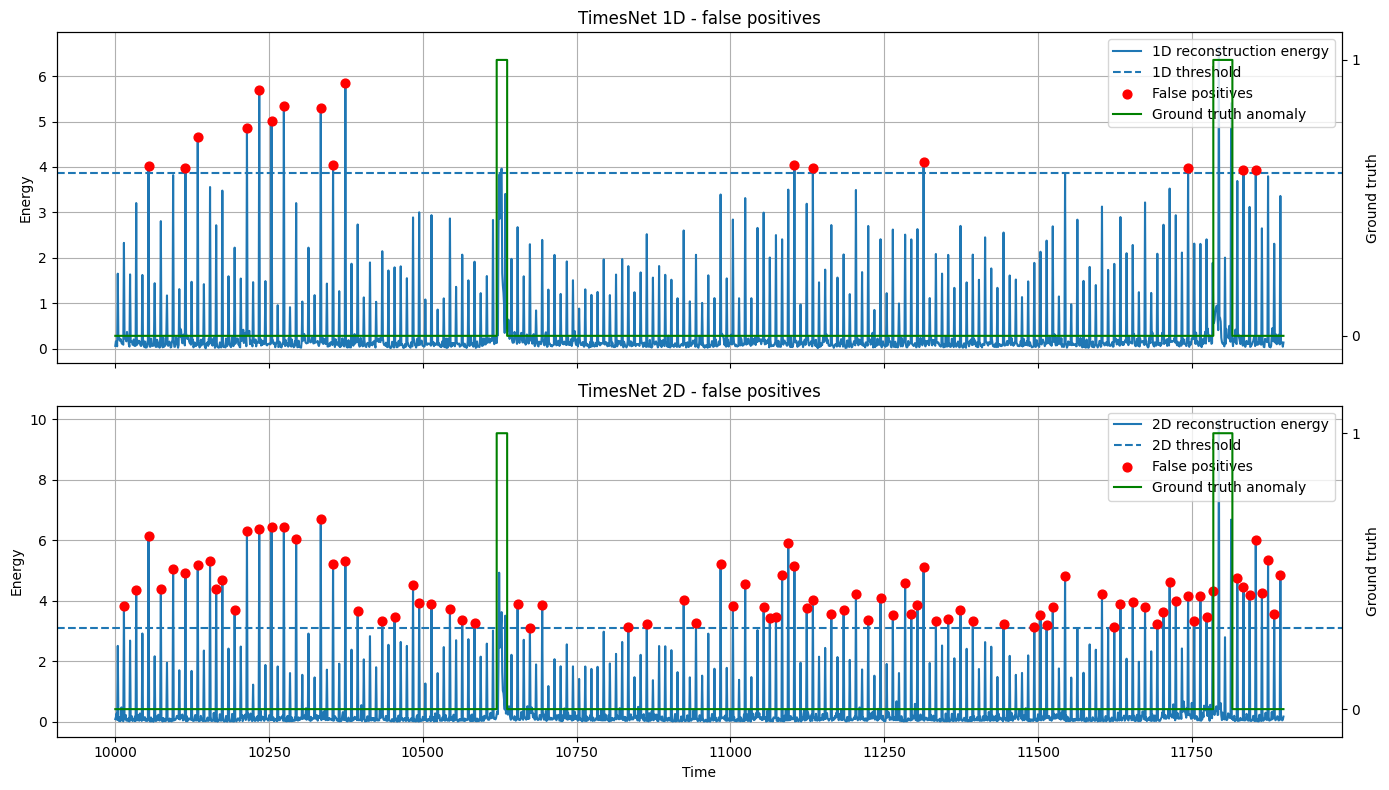

In [40]:
start = 10000
end = 11900
x = np.arange(start, end)

# ---------- 1D ----------
pred_1d = (energy_1d > result_1d["threshold"]).astype(int)
fp_1d = (pred_1d == 1) & (gt_1d == 0)

# ---------- 2D ----------
pred_2d = (energy_2d > result_2d["threshold"]).astype(int)
fp_2d = (pred_2d == 1) & (gt_2d == 0)

fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# =======================
# 1D
# =======================
ax[0].plot(
    x,
    energy_1d[start:end],
    label="1D reconstruction energy",
    linewidth=1.5
)

ax[0].axhline(
    result_1d["threshold"],
    linestyle="--",
    label="1D threshold"
)

# falsi positivi come punti rossi
fp_idx_1d = np.where(fp_1d[start:end])[0] + start
ax[0].scatter(
    fp_idx_1d,
    energy_1d[fp_idx_1d],
    color="red",
    s=40,
    marker="o",
    label="False positives",
    zorder=5
)

# ground truth su asse secondario
ax0_gt = ax[0].twinx()
ax0_gt.step(
    x,
    gt_1d[start:end],
    where="post",
    color="green",
    linewidth=1.5,
    label="Ground truth anomaly"
)
ax0_gt.set_ylim(-0.1, 1.1)
ax0_gt.set_yticks([0, 1])
ax0_gt.set_ylabel("Ground truth")

ax[0].set_title("TimesNet 1D - false positives")
ax[0].set_ylabel("Energy")
ax[0].grid()

lines1, labels1 = ax[0].get_legend_handles_labels()
lines2, labels2 = ax0_gt.get_legend_handles_labels()
ax[0].legend(lines1 + lines2, labels1 + labels2, loc="upper right")


# =======================
# 2D
# =======================
ax[1].plot(x, energy_2d[start:end], label="2D reconstruction energy", linewidth=1.5)
ax[1].axhline(result_2d["threshold"], linestyle="--", label="2D threshold")

# falsi positivi come punti rossi
fp_idx_2d = np.where(fp_2d[start:end])[0] + start
ax[1].scatter(
    fp_idx_2d,
    energy_2d[fp_idx_2d],
    color="red",
    s=40,
    marker="o",
    label="False positives",
    zorder=5
)

# ground truth su asse secondario
ax1_gt = ax[1].twinx()
ax1_gt.step(
    x,
    gt_2d[start:end],
    where="post",
    color="green",
    linewidth=1.5,
    label="Ground truth anomaly"
)
ax1_gt.set_ylim(-0.1, 1.1)
ax1_gt.set_yticks([0, 1])
ax1_gt.set_ylabel("Ground truth")

ax[1].set_title("TimesNet 2D - false positives")
ax[1].set_xlabel("Time")
ax[1].set_ylabel("Energy")
ax[1].grid()

lines1, labels1 = ax[1].get_legend_handles_labels()
lines2, labels2 = ax1_gt.get_legend_handles_labels()
ax[1].legend(lines1 + lines2, labels1 + labels2, loc="upper right")

plt.tight_layout()
plt.show()

# Optional: comparison over multiple seeds

A single run is not sufficient to establish that one architecture is consistently better.

Set:

```python
RUN_MULTI_SEED = True
```

to train the four models with 7 seeds. The cell saves all runs to `timesnet_multi_seed_results.csv` and reports mean and standard deviation.

In [41]:
RUN_MULTI_SEED = True

seeds = [
    2021, 2022, 2023, 2024, 2025,
    2026, 2027
]

model_configs = [
    (0, "TimesNet 1D - no periodicity"),
    (1, "TimesNet 1D - periodicity"),
    (2, "TimesNet 2D - periodic"),
    (3, "TimesNet 2D - fractional")
]

results_path = "timesnet_multi_seed_results.csv"

if RUN_MULTI_SEED:
    results = []

    for current_seed in seeds:
        for block_type, model_name in model_configs:

            print("\n" + "=" * 70)
            print(f"Seed: {current_seed} - {model_name}")
            print("=" * 70)

            model, history, training_time = train_model(
                block_type=block_type,
                seed=current_seed,
                model_name=f"TimesNet_dim_{block_type}"
            )

            result, _, _, _, _ = evaluate_model(
                model,
                model_name=model_name,
                training_time=training_time
            )

            result["seed"] = current_seed
            result["block_type"] = block_type
            results.append(result)

            del model

            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    multi_seed_results = pd.DataFrame(results)
    multi_seed_results.to_csv(results_path, index=False)

    print(f"\nResults saved to: {results_path}")
    display(multi_seed_results)

else:
    print("Multi-seed experiment disabled.")


Seed: 2021 - TimesNet 1D - no periodicity
Epoch: 1, Train Loss: 0.2588010, Vali Loss: 0.2715189, Time: 1.91s
Validation loss decreased. Saving model ...
Learning rate 0.0001
Epoch: 2, Train Loss: 0.2193821, Vali Loss: 0.2560818, Time: 1.93s
Validation loss decreased. Saving model ...
Learning rate 5e-05
Epoch: 3, Train Loss: 0.2060712, Vali Loss: 0.2495755, Time: 1.94s
Validation loss decreased. Saving model ...
Learning rate 2.5e-05
Epoch: 4, Train Loss: 0.2004759, Vali Loss: 0.2464614, Time: 1.92s
Validation loss decreased. Saving model ...
Learning rate 1.25e-05
Epoch: 5, Train Loss: 0.1977931, Vali Loss: 0.2448459, Time: 1.91s
Validation loss decreased. Saving model ...
Learning rate 6.25e-06
Epoch: 6, Train Loss: 0.1951632, Vali Loss: 0.2440487, Time: 1.94s
Validation loss decreased. Saving model ...
Learning rate 3.125e-06
Epoch: 7, Train Loss: 0.1947269, Vali Loss: 0.2436384, Time: 1.93s
Validation loss decreased. Saving model ...
Learning rate 1.5625e-06
Epoch: 8, Train Loss: 

,model,parameters,training_time,threshold,raw_accuracy,raw_precision,raw_recall,raw_f1,accuracy,precision,recall,f1,seed,block_type
0,TimesNet 1D - no periodicity,896934,19.474873,3.000512,0.952781,0.246070,0.065922,0.103986,0.984920,0.806002,0.839152,0.822243,2021,0
1,TimesNet 1D - periodicity,1119270,34.510494,3.453582,0.953564,0.262753,0.064903,0.104093,0.986078,0.823071,0.847168,0.834946,2021,1
2,TimesNet 2D - periodic,7040934,145.451648,2.865208,0.953509,0.273023,0.071288,0.113056,0.985318,0.815062,0.836571,0.825677,2021,2
3,TimesNet 2D - fractional,7040934,139.159362,2.867451,0.953533,0.273746,0.071356,0.113203,0.985339,0.815467,0.836571,0.825884,2021,3
4,TimesNet 1D - no periodicity,896934,19.263427,3.876134,0.954145,0.266370,0.058857,0.096412,0.984935,0.831450,0.799654,0.815242,2022,0
5,TimesNet 1D - periodicity,1119270,35.387985,2.983636,0.952804,0.259407,0.073054,0.114003,0.984380,0.799713,0.832767,0.815905,2022,1
6,TimesNet 2D - periodic,7040934,144.281578,3.082346,0.953300,0.267093,0.070846,0.111988,0.985103,0.811332,0.835994,0.823478,2022,2
7,TimesNet 2D - fractional,7040934,135.259014,3.082078,0.953303,0.267994,0.071322,0.112661,0.985086,0.811011,0.835994,0.823313,2022,3
8,TimesNet 1D - no periodicity,896934,19.444600,3.033330,0.953646,0.277625,0.071933,0.114261,0.985539,0.817649,0.839254,0.828311,2023,0
9,TimesNet 1D - periodicity,1119270,34.657132,3.263838,0.953422,0.266008,0.068571,0.109035,0.985639,0.816822,0.843703,0.830045,2023,1


In [42]:
multi_seed_results = pd.read_csv("timesnet_multi_seed_results.csv")

metrics = [
    "raw_precision",
    "raw_recall",
    "raw_f1",
    "precision",
    "recall",
    "f1",
    "training_time"
]

# Numerical summary
summary = (
    multi_seed_results
    .groupby("model")[metrics]
    .agg(["mean", "std"])
)

display(summary)

# Compact report-ready table
report_rows = []

for model_name, model_data in multi_seed_results.groupby("model"):
    report_rows.append({
        "Model": model_name,
        "Parameters": int(model_data["parameters"].iloc[0]),
        "Raw F1": (
            f"{model_data['raw_f1'].mean():.4f} ± "
            f"{model_data['raw_f1'].std():.4f}"
        ),
        "Adjusted Precision": (
            f"{model_data['precision'].mean():.4f} ± "
            f"{model_data['precision'].std():.4f}"
        ),
        "Adjusted Recall": (
            f"{model_data['recall'].mean():.4f} ± "
            f"{model_data['recall'].std():.4f}"
        ),
        "Adjusted F1": (
            f"{model_data['f1'].mean():.4f} ± "
            f"{model_data['f1'].std():.4f}"
        ),
        "Training time [s]": (
            f"{model_data['training_time'].mean():.2f} ± "
            f"{model_data['training_time'].std():.2f}"
        )
    })

report_summary = pd.DataFrame(report_rows)

display(report_summary)

raw_precision           raw_recall            \
                                      mean       std       mean       std   
model                                                                       
TimesNet 1D - no periodicity      0.265009  0.012906   0.066208  0.004542   
TimesNet 1D - periodicity         0.261650  0.005304   0.068100  0.003923   
TimesNet 2D - fractional          0.272482  0.005272   0.068804  0.001919   
TimesNet 2D - periodic            0.271157  0.005118   0.068605  0.001879   

                                raw_f1           precision            \
                                  mean       std      mean       std   
model                                                                  
TimesNet 1D - no periodicity  0.105857  0.006077  0.818761  0.011089   
TimesNet 1D - periodicity     0.108027  0.005076  0.813887  0.008684   
TimesNet 2D - fractional      0.109842  0.002307  0.820148  0.007061   
TimesNet 2D - periodic        0.109481  0.002258  0.819592  0.006848   

                                recall                  f1            \
                                  mean       std      mean       std   
model                                                                  
TimesNet 1D - no periodicity  0.829992  0.015318  0.824178  0.005046   
TimesNet 1D - periodicity     0.840094  0.006410  0.826763  0.006318   
TimesNet 2D - fractional      0.838099  0.006145  0.829013  0.005582   
TimesNet 2D - periodic        0.838099  0.006145  0.828728  0.005333   

                             training_time            
                                      mean       std  
model                                                 
TimesNet 1D - no periodicity     19.507948  0.254971  
TimesNet 1D - periodicity        34.879023  0.470124  
TimesNet 2D - fractional        135.300791  1.751494  
TimesNet 2D - periodic          143.994845  0.739863

,Model,Parameters,Raw F1,Adjusted Precision,Adjusted Recall,Adjusted F1,Training time [s]
0,TimesNet 1D - no periodicity,896934,0.1059 ± 0.0061,0.8188 ± 0.0111,0.8300 ± 0.0153,0.8242 ± 0.0050,19.51 ± 0.25
1,TimesNet 1D - periodicity,1119270,0.1080 ± 0.0051,0.8139 ± 0.0087,0.8401 ± 0.0064,0.8268 ± 0.0063,34.88 ± 0.47
2,TimesNet 2D - fractional,7040934,0.1098 ± 0.0023,0.8201 ± 0.0071,0.8381 ± 0.0061,0.8290 ± 0.0056,135.30 ± 1.75
3,TimesNet 2D - periodic,7040934,0.1095 ± 0.0023,0.8196 ± 0.0068,0.8381 ± 0.0061,0.8287 ± 0.0053,143.99 ± 0.74


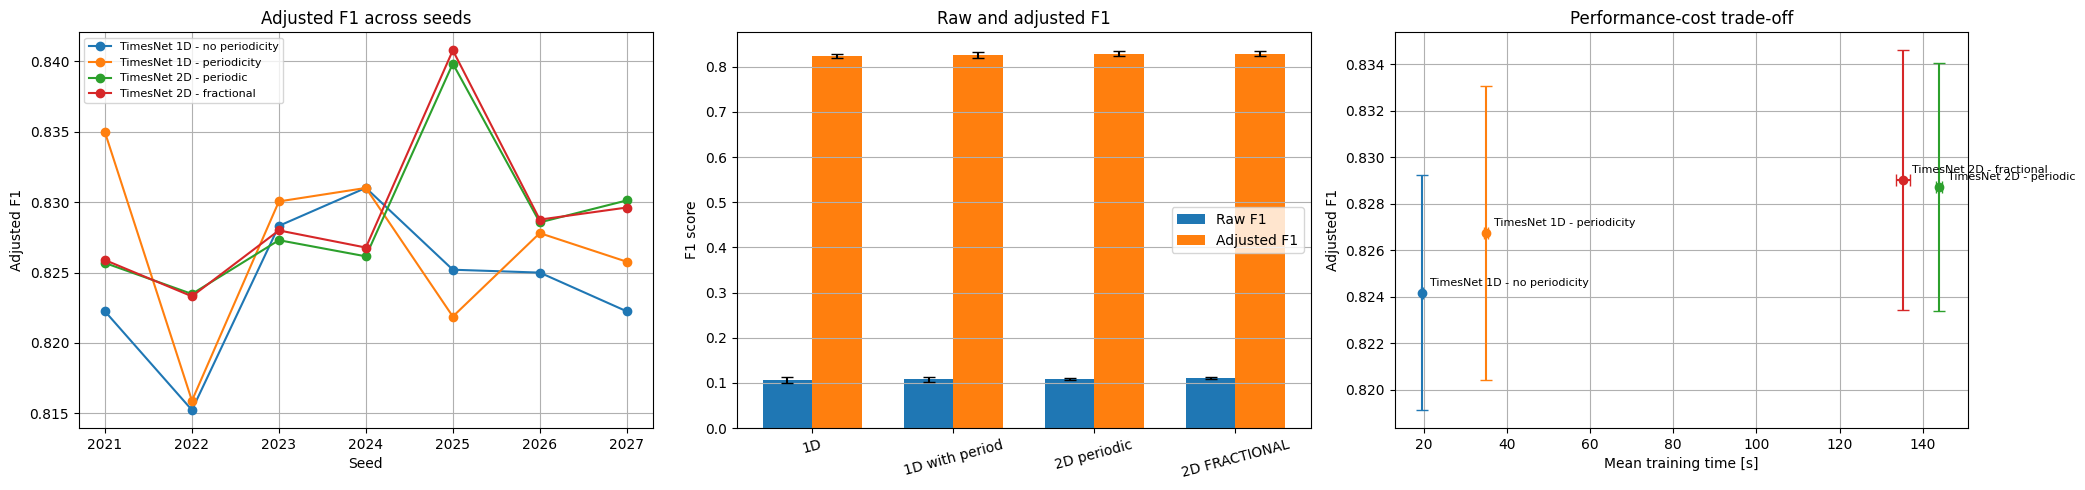

In [43]:
model_order = [
    "TimesNet 1D - no periodicity",
    "TimesNet 1D - periodicity",
    "TimesNet 2D - periodic",
    "TimesNet 2D - fractional"
]

# Aggregate values used by the plots
plot_summary = (
    multi_seed_results
    .groupby("model")
    .agg(
        raw_f1_mean=("raw_f1", "mean"),
        raw_f1_std=("raw_f1", "std"),
        f1_mean=("f1", "mean"),
        f1_std=("f1", "std"),
        training_time_mean=("training_time", "mean"),
        training_time_std=("training_time", "std")
    )
    .reindex(model_order)
    .reset_index()
)

fig, axes = plt.subplots(1, 3, figsize=(21, 5))


# 1. Adjusted F1 across seeds
for model_name in model_order:
    model_data = (
        multi_seed_results[
            multi_seed_results["model"] == model_name
        ]
        .sort_values("seed")
    )

    axes[0].plot(
        model_data["seed"],
        model_data["f1"],
        marker="o",
        label=model_name
    )

axes[0].set_title("Adjusted F1 across seeds")
axes[0].set_xlabel("Seed")
axes[0].set_ylabel("Adjusted F1")
axes[0].set_xticks(seeds)
axes[0].grid()
axes[0].legend(fontsize=8)


# 2. Raw versus adjusted F1
x = np.arange(len(plot_summary))
width = 0.35

axes[1].bar(
    x - width / 2,
    plot_summary["raw_f1_mean"],
    width,
    yerr=plot_summary["raw_f1_std"],
    capsize=4,
    label="Raw F1"
)

axes[1].bar(
    x + width / 2,
    plot_summary["f1_mean"],
    width,
    yerr=plot_summary["f1_std"],
    capsize=4,
    label="Adjusted F1"
)

axes[1].set_title("Raw and adjusted F1")
axes[1].set_ylabel("F1 score")
axes[1].set_xticks(x)
axes[1].set_xticklabels(
    ["1D", "1D with period", "2D periodic", "2D FRACTIONAL"],
    rotation=15
)
axes[1].grid(axis="y")
axes[1].legend()


# 3. Training time versus adjusted F1
for _, row in plot_summary.iterrows():
    axes[2].errorbar(
        row["training_time_mean"],
        row["f1_mean"],
        xerr=row["training_time_std"],
        yerr=row["f1_std"],
        marker="o",
        capsize=4
    )

    axes[2].annotate(
        row["model"],
        (
            row["training_time_mean"],
            row["f1_mean"]
        ),
        xytext=(6, 5),
        textcoords="offset points",
        fontsize=8
    )

axes[2].set_title("Performance-cost trade-off")
axes[2].set_xlabel("Mean training time [s]")
axes[2].set_ylabel("Adjusted F1")
axes[2].grid()

plt.tight_layout()
plt.show()

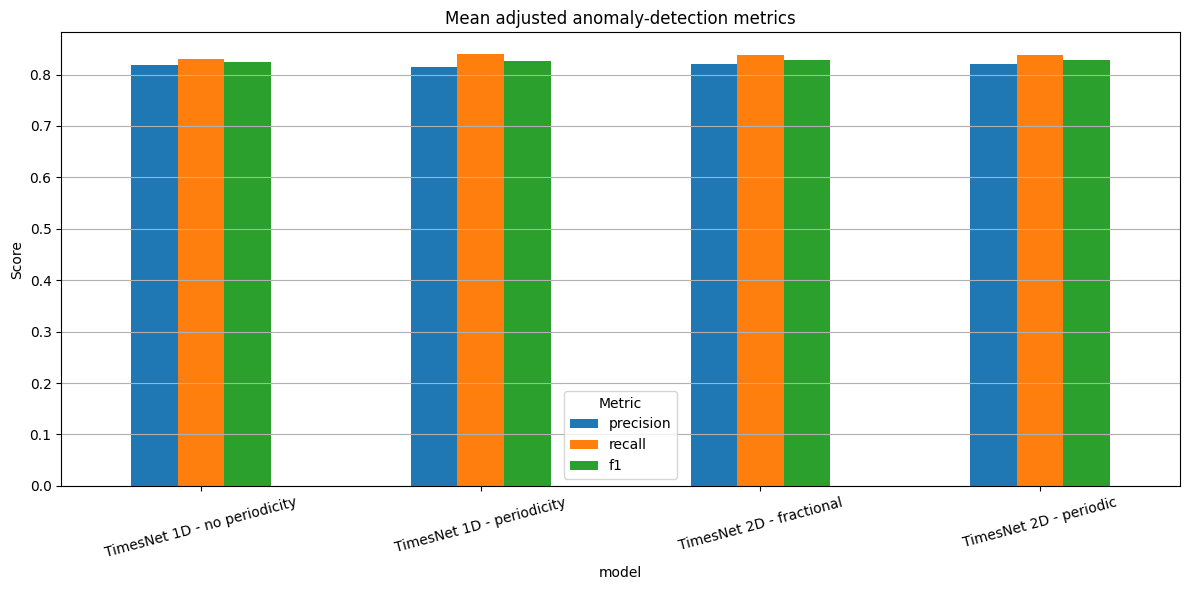

In [44]:
metric_means = (
    multi_seed_results
    .groupby("model")[["precision", "recall", "f1"]]
    .mean()
)

metric_means.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.ylabel("Score")
plt.title("Mean adjusted anomaly-detection metrics")
plt.xticks(rotation=15)
plt.grid(axis="y")
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

# Conclusions

In this notebook, I studied the TimesNet architecture on the SMD dataset, comparing it with other approaches that start from the ideas used in TimesNet.

From the results, we can conclude that there is a benefit in using the 2D approach, with better results in terms of adjusted F1-score. However, we can notice that the impact is not very strong in this implementation, since the difference between the worst model (TimesNet 1D - no periodicity) and the best model (2D - fractional) is only 0.0048 in terms of F1-score, which measures the harmonic mean of precision and recall.

We can also observe that introducing inter-period information while keeping the convolution one-dimensional improves the results. In my view, there may be two reasons for this. The first is the actual capture of periodic dependencies. The second is that the use of two types of kernels, local and inter-period 1D convolutions, increases the number of parameters, so the model may simply be more capable of learning. However, increasing the number of parameters can also increase the risk of overfitting. Therefore, it is not straightforward to say that a higher number of parameters necessarily leads to better results.

Moreover, the proposal in *Improvement of Anomaly Detection Through Enhanced Feature Extraction in TimesNet* leads to some observations. First, when tested on the SMD dataset, the modified padding does not produce a meaningful improvement in anomaly-detection performance. The other observation is that the training time decreases. Since the main difference between 1D and 2D models is the training time, which is also related to their number of parameters, introducing padding within each period by repeating the last value appears to speed up training.